
# NMR titration pKa fitting with Bayesian bootstrap

This notebook fits an NMR titration curve to estimate a pKa value using:

$$
\delta_{\mathrm{pred}} = \frac{\delta_1 + \delta_2\,10^{\mathrm{pH}-\mathrm{p}K_a}}{1 + 10^{\mathrm{pH}-\mathrm{p}K_a}}
$$

where $\delta_1$ is the low-pH chemical-shift limit, $\delta_2$ is the high-pH chemical-shift limit, and $\mathrm{p}K_a$ is the fitted midpoint.

Uncertainty is estimated using bayesian bootstrapping: each bootstrap replicate draws Dirichlet-distributed weights over the observed data points, then refits the weighted nonlinear least-squares model.


In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit, least_squares

pd.set_option("display.precision", 4)

# Publication-style plotting defaults.
plt.rcParams.update({
    "figure.figsize": (7, 4.5),
    "font.family": "Arial",
    "axes.grid": False,
})


def style_nmr_axis(ax):
    """Apply the requested plot styling."""
    ax.grid(False)
    ax.tick_params(direction="in", which="both", top=False, right=False)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    return ax



## 1. Load the titration data

The notebook expects the Excel file to be in the same folder as this notebook. Update `excel_path` if needed.


In [2]:

excel_path = Path("p5_titration.xlsx")

raw = pd.read_excel(excel_path, sheet_name=0)
raw


,nr,pH,NMR_shift
0,1,3.32,-5.03
1,2,3.97,-4.28
2,3,4.85,-1.90
3,4,5.29,-1.01
4,5,5.85,-0.49
5,6,6.44,-0.36
6,7,7.04,-0.42
7,8,7.40,-0.42
8,9,7.93,-0.33
9,10,8.94,-0.35


In [3]:

# Choose columns. Change these if your spreadsheet has different headers.
pH_col = "pH"
shift_col = "NMR_shift"

data = raw[[pH_col, shift_col]].copy()
data[pH_col] = pd.to_numeric(data[pH_col], errors="coerce")
data[shift_col] = pd.to_numeric(data[shift_col], errors="coerce")
data = data.dropna().sort_values(pH_col).reset_index(drop=True)

pH = data[pH_col].to_numpy(dtype=float)
shift = data[shift_col].to_numpy(dtype=float)

print(f"Loaded {len(data)} titration points from {excel_path.name}")
display(data)


Loaded 10 titration points from p5_titration.xlsx


,pH,NMR_shift
0,3.32,-5.03
1,3.97,-4.28
2,4.85,-1.90
3,5.29,-1.01
4,5.85,-0.49
5,6.44,-0.36
6,7.04,-0.42
7,7.40,-0.42
8,7.93,-0.33
9,8.94,-0.35


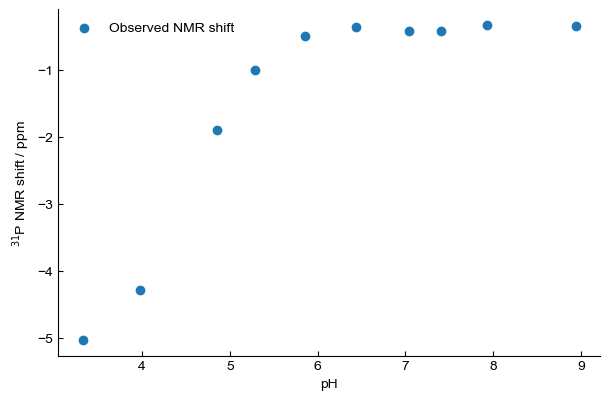

In [4]:
fig, ax = plt.subplots()
ax.scatter(pH, shift, label="Observed NMR shift")
ax.set_xlabel("pH")
ax.set_ylabel(r"$^{31}$P NMR shift / ppm")
style_nmr_axis(ax)
ax.legend(frameon=False)
plt.show()



## 2. Define the titration model and fit by nonlinear least squares


In [5]:

def titration_model(pH, delta1, delta2, pKa):
    "Two-state pH titration model for the predicted chemical shift."
    ratio = 10 ** (pH - pKa)
    return (delta1 + delta2 * ratio) / (1 + ratio)

initial_guess = np.array([
    shift[np.argmin(pH)],
    shift[np.argmax(pH)],
    np.median(pH),
], dtype=float)

# Keep pKa in a broad but finite range to stabilize bootstrap replicates.
lower_bounds = [-np.inf, -np.inf, pH.min() - 3]
upper_bounds = [ np.inf,  np.inf, pH.max() + 3]

popt, pcov = curve_fit(
    titration_model,
    pH,
    shift,
    p0=initial_guess,
    bounds=(lower_bounds, upper_bounds),
    maxfev=50_000,
)

param_names = ["delta1_low_pH", "delta2_high_pH", "pKa"]
fit_summary = pd.DataFrame({
    "parameter": param_names,
    "estimate": popt,
    "asymptotic_SE": np.sqrt(np.diag(pcov)),
})
fit_summary


,parameter,estimate,asymptotic_SE
0,delta1_low_pH,-5.3749,0.0610
1,delta2_high_pH,-0.3429,0.0226
2,pKa,4.5007,0.0232


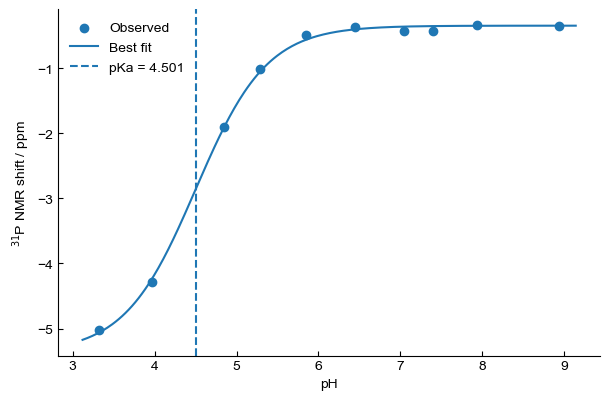

In [6]:
pH_grid = np.linspace(pH.min() - 0.2, pH.max() + 0.2, 300)
fit_grid = titration_model(pH_grid, *popt)

fig, ax = plt.subplots()
ax.scatter(pH, shift, label="Observed")
ax.plot(pH_grid, fit_grid, label="Best fit")
ax.axvline(popt[2], linestyle="--", label=f"pKa = {popt[2]:.3f}")
ax.set_xlabel("pH")
ax.set_ylabel(r"$^{31}$P NMR shift / ppm")
style_nmr_axis(ax)
ax.legend(frameon=False)
plt.show()



## 3. Bayesian bootstrap uncertainty analysis

For each bootstrap replicate:

1. Draw weights $w \sim \mathrm{Dirichlet}(1, 1, \ldots, 1)$ across the observed data points.
2. Refit the model by minimizing the weighted residual sum of squares.
3. Store $\delta_1$, $\delta_2$, and $\mathrm{p}K_a$.

The resulting distribution reflects uncertainty from the empirical data distribution without assuming a parametric residual distribution.


In [7]:

def fit_weighted_titration(weights, start_params):
    "Fit model with Bayesian-bootstrap weights."
    weights = np.asarray(weights, dtype=float)

    def weighted_residuals(params):
        return np.sqrt(weights) * (titration_model(pH, *params) - shift)

    result = least_squares(
        weighted_residuals,
        x0=start_params,
        bounds=(lower_bounds, upper_bounds),
        max_nfev=50_000,
    )
    return result.x, result.cost, result.success

# Increase n_boot for publication-quality intervals if desired.
n_boot = 5000
rng = np.random.default_rng(20260701)

boot_params = np.empty((n_boot, 3), dtype=float)
boot_cost = np.empty(n_boot, dtype=float)
boot_success = np.zeros(n_boot, dtype=bool)

for i in range(n_boot):
    weights = rng.dirichlet(np.ones(len(pH)))
    params_i, cost_i, success_i = fit_weighted_titration(weights, start_params=popt)
    boot_params[i] = params_i
    boot_cost[i] = cost_i
    boot_success[i] = success_i

boot = pd.DataFrame(boot_params, columns=param_names)
boot["cost"] = boot_cost
boot["success"] = boot_success

print(f"Successful fits: {boot['success'].sum()} / {n_boot}")
boot = boot.loc[boot["success"]].reset_index(drop=True)
boot.head()


Successful fits: 5000 / 5000


,delta1_low_pH,delta2_high_pH,pKa,cost,success
0,-5.4395,-0.3538,4.4907,0.0009,True
1,-5.3847,-0.3375,4.5011,0.0007,True
2,-5.4818,-0.3526,4.4780,0.0009,True
3,-5.3393,-0.3971,4.5009,0.0004,True
4,-5.3556,-0.3345,4.5186,0.0011,True


In [8]:

summary = boot[param_names].quantile([0.025, 0.5, 0.975]).T
summary.columns = ["2.5%", "median", "97.5%"]
summary.insert(0, "least_squares_estimate", popt)
summary


,least_squares_estimate,2.5%,median,97.5%
delta1_low_pH,-5.3749,-5.5168,-5.3764,-5.3385
delta2_high_pH,-0.3429,-0.3820,-0.3439,-0.3055
pKa,4.5007,4.4599,4.4967,4.5231


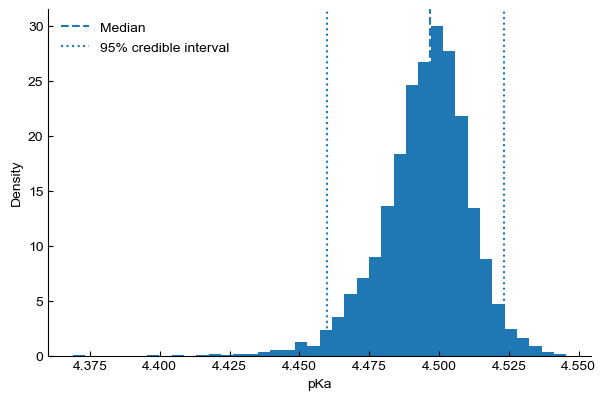

In [9]:
fig, ax = plt.subplots()
ax.hist(boot["pKa"], bins=40, density=True)
ax.axvline(summary.loc["pKa", "median"], linestyle="--", label="Median")
ax.axvline(summary.loc["pKa", "2.5%"], linestyle=":", label="95% credible interval")
ax.axvline(summary.loc["pKa", "97.5%"], linestyle=":")
ax.set_xlabel("pKa")
ax.set_ylabel("Density")
style_nmr_axis(ax)
ax.legend(frameon=False)
plt.show()


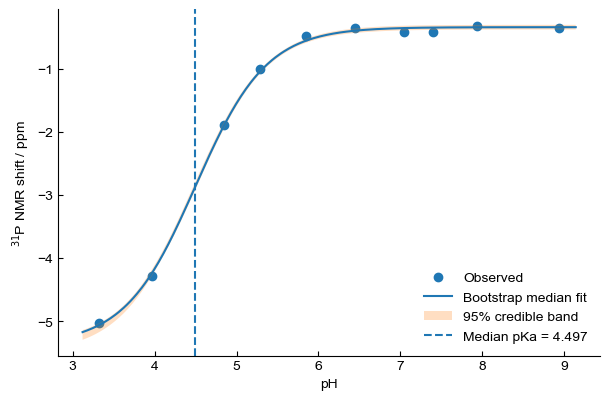

In [10]:
band_draws = boot[param_names].sample(n=min(2000, len(boot)), random_state=1).to_numpy()
curves = np.array([titration_model(pH_grid, *params) for params in band_draws])
curve_lower, curve_median, curve_upper = np.quantile(curves, [0.025, 0.5, 0.975], axis=0)

fig, ax = plt.subplots()
ax.scatter(pH, shift, label="Observed")
ax.plot(pH_grid, curve_median, label="Bootstrap median fit")
ax.fill_between(pH_grid, curve_lower, curve_upper, alpha=0.25, label="95% credible band")
ax.axvline(summary.loc["pKa", "median"], linestyle="--", label=f"Median pKa = {summary.loc['pKa', 'median']:.3f}")
ax.set_xlabel("pH")
ax.set_ylabel(r"$^{31}$P NMR shift / ppm")
style_nmr_axis(ax)
ax.legend(frameon=False)
plt.show()



## 4. Export numerical results

The next cell writes the fitted parameters, Bayesian-bootstrap draws, and cleaned input data to CSV files.


In [11]:

output_dir = Path("nmr_titration_outputs")
output_dir.mkdir(exist_ok=True)

data.to_csv(output_dir / "cleaned_titration_data.csv", index=False)
fit_summary.to_csv(output_dir / "least_squares_fit_summary.csv", index=False)
summary.to_csv(output_dir / "bayesian_bootstrap_summary.csv")
boot.to_csv(output_dir / "bayesian_bootstrap_draws.csv", index=False)

print(f"Wrote results to: {output_dir.resolve()}")


Wrote results to: /Users/robertmayer/Desktop/mayerlab/Research/project_phosph_transfer/pka/p5_titration/nmr_titration_outputs



## Interpretation template

Report the pKa as the Bayesian-bootstrap median with the 95% credible interval:

```text
pKa = [median] ([2.5%], [97.5%])
```

For this model, $\delta_1$ is the fitted low-pH shift limit and $\delta_2$ is the fitted high-pH shift limit. Inspect the fitted curve and residuals before treating the pKa as final, especially if any points are suspected outliers or if chemical exchange/aggregation introduces non-two-state behavior.
